In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("../src")

from spatiotemporal_yield_loss_estimation import construct_lec_curve

In [2]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica"],
    "font.size": 11,
    "axes.linewidth": 1,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 1,
    "ytick.major.width": 1,
})

## plot

In [31]:
crop_name = "sugarcane"
plot_output_path = f"../../fig/lec_{crop_name}.svg"

country_codes = ["ID", "KH", "MM", "PH", "TH", "VN"]

ylr = {}

for country_code in country_codes:
    yield_df = pd.read_csv(
        f"../../Results/4.1_SpatiotemporalYieldLoss/"
        f"country_yield_{crop_name}_{country_code.lower()}.csv"
    )
    ylr[country_code] = yield_df["ylr"]

max_ylr = max(series.max() for series in ylr.values())
print(f"Max ylr: {max_ylr:.3f}")

Max ylr: 0.209


In [26]:
[round(float(series.mean()),3) for series in ylr.values()]

[0.003, 0.03, 0.371, 0.032, 0.049, 0.06]

In [28]:
[round(float(series.mean()),3) for series in ylr.values()]

[0.017, 0.0, 0.052, 0.026, 0.007, 0.004]

In [30]:
[round(float(series.mean()),3) for series in ylr.values()]

[0.095, 0.064, 0.119, 0.091, 0.083, 0.098]

In [32]:
[round(float(series.mean()),3) for series in ylr.values()]

[0.039, 0.017, 0.016, 0.036, 0.047, 0.023]

In [23]:
[round(float(series.mean()),3) for series in ylr.values()]

[0.016, 0.018, 0.001, 0.016, 0.018, 0.012]

In [16]:
lec = {}

for country_code, series in ylr.items():
    return_period, losses = construct_lec_curve(series)
    lec[country_code] = {
        "return_period": return_period,
        "losses": losses,
    }

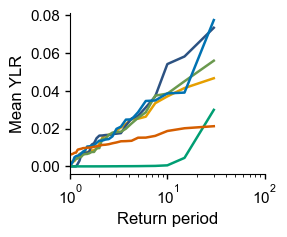

In [17]:
colors = ["#E69F00", "#2C5282", "#009E73", "#6A994E", "#0072B2", "#D55E00"]

fig, ax = plt.subplots(figsize=(3,2.5))

for i,country_code in enumerate(country_codes):
    ax.plot(
        lec[country_code]["return_period"],
        lec[country_code]["losses"],
        color=colors[i],
        linewidth=1.8,
        label=country_code,
    )

ax.set_xlim([1,100])
ax.set_xscale("log")

ax.set_xlabel("Return period")
ax.set_ylabel("Mean YLR")
#ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5), frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)
plt.tight_layout()
plt.savefig(plot_output_path, bbox_inches="tight", dpi = 300)